
# Mini projekat 2 – ML eksperimentalni framework

**Autor:** Ivona Dabović  
**Predmet:** Napredne programske tehnike

## Opis projekta

Cilj projekta je razvoj jednostavnog frameworka za izvođenje eksperimenata mašinskog učenja primjenom objektno-orijentisanog programiranja i dizajn paterna.

U projektu će biti implementirani Factory, Strategy, Observer, Template Method i Decorator obrasci.


In [1]:
!pip install scikit-learn pandas numpy pytest

In [4]:
import time
from abc import ABC, abstractmethod
from typing import Protocol
from functools import wraps

import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

In [5]:
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn je uspjesno ucitan!")
print("Okruzenje je spremno!")

NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn je uspjesno ucitan!
Okruzenje je spremno!


In [6]:
iris = load_iris()

X = iris.data
y = iris.target

print("Broj uzoraka:", X.shape[0])
print("Broj karakteristika:", X.shape[1])
print("Klase:", iris.target_names)
print("Dimenzije X:", X.shape)
print("Dimenzije y:", y.shape)

Broj uzoraka: 150
Broj karakteristika: 4
Klase: ['setosa' 'versicolor' 'virginica']
Dimenzije X: (150, 4)
Dimenzije y: (150,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Trening uzorci:", len(X_train))
print("Test uzorci:", len(X_test))

Trening uzorci: 120
Test uzorci: 30



## 1. Factory pattern

Factory obrazac omogućava kreiranje različitih modela mašinskog učenja bez potrebe da ostatak programa poznaje detalje njihove konstrukcije.


In [8]:
class MLModel(ABC):
    @abstractmethod
    def train(self, X, y):
        pass

    @abstractmethod
    def predict(self, X):
        pass

In [9]:
class LogisticRegressionModel(MLModel):
    def __init__(self):
        self.model = LogisticRegression(max_iter=200)

    def train(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)


class DecisionTreeModel(MLModel):
    def __init__(self):
        self.model = DecisionTreeClassifier(random_state=42)

    def train(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)


class KNNModel(MLModel):
    def __init__(self):
        self.model = KNeighborsClassifier(n_neighbors=5)

    def train(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)


### Factory – kreiranje modela

Factory klasa centralizuje kreiranje modela. Na osnovu naziva algoritma vraća odgovarajuću instancu modela.


In [10]:
class ModelFactory:

    @staticmethod
    def create_model(model_type: str) -> MLModel:

        models = {
            "logistic_regression": LogisticRegressionModel,
            "decision_tree": DecisionTreeModel,
            "knn": KNNModel,
        }

        if model_type not in models:
            raise ValueError(f"Nepoznat model: {model_type}")

        return models[model_type]()

In [11]:
modeli = [
    "logistic_regression",
    "decision_tree",
    "knn",
]

for naziv in modeli:
    model = ModelFactory.create_model(naziv)
    print(naziv, "->", type(model).__name__)

logistic_regression -> LogisticRegressionModel
decision_tree -> DecisionTreeModel
knn -> KNNModel



## 2. Strategy pattern

Strategy obrazac omogućava da se različite strategije za evaluaciju modela međusobno mijenjaju bez izmjene ostatka frameworka.

Koristićemo Accuracy, Precision, Recall i F1-score.


In [12]:
class MetricStrategy(ABC):

    @abstractmethod
    def calculate(self, y_true, y_pred):
        pass


class AccuracyStrategy(MetricStrategy):
    def calculate(self, y_true, y_pred):
        return accuracy_score(y_true, y_pred)


class PrecisionStrategy(MetricStrategy):
    def calculate(self, y_true, y_pred):
        return precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        )


class RecallStrategy(MetricStrategy):
    def calculate(self, y_true, y_pred):
        return recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        )


class F1Strategy(MetricStrategy):
    def calculate(self, y_true, y_pred):
        return f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )


## 3. Observer pattern

Observer obrazac omogućava da jedan objekat obavještava druge objekte o promjenama svog stanja.

U našem frameworku koristićemo ga za praćenje početka i završetka treniranja modela.


In [13]:
class Observer(ABC):

    @abstractmethod
    def update(self, message: str):
        pass


class TrainingLogger(Observer):

    def update(self, message: str):
        print(f"[OBSERVER] {message}")


class ExperimentMonitor:

    def __init__(self):
        self.observers = []

    def subscribe(self, observer: Observer):
        self.observers.append(observer)

    def notify(self, message: str):
        for observer in self.observers:
            observer.update(message)

In [14]:
monitor = ExperimentMonitor()

logger = TrainingLogger()
monitor.subscribe(logger)

monitor.notify("Eksperiment je zapocet.")
monitor.notify("Model je uspjesno istreniran.")
monitor.notify("Evaluacija je zavrsena.")

[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Model je uspjesno istreniran.
[OBSERVER] Evaluacija je zavrsena.



## 4. Decorator pattern

Decorator obrazac omogućava dodavanje dodatne funkcionalnosti postojećoj funkciji bez izmjene njenog osnovnog koda.

U našem projektu koristićemo ga za mjerenje vremena potrebnog za izvršavanje eksperimenta.


In [15]:
def measure_time(function):

    @wraps(function)
    def wrapper(*args, **kwargs):
        start = time.perf_counter()

        result = function(*args, **kwargs)

        end = time.perf_counter()
        elapsed = end - start

        print(f"[DECORATOR] Vrijeme izvrsavanja: {elapsed:.6f} sekundi")

        return result

    return wrapper

In [16]:
@measure_time
def test_function():
    time.sleep(1)
    return "Test je uspjesno zavrsen!"


rezultat = test_function()
print(rezultat)

[DECORATOR] Vrijeme izvrsavanja: 1.000157 sekundi
Test je uspjesno zavrsen!



## 5. Template Method pattern

Template Method obrazac definiše osnovni redosljed koraka eksperimenta, dok pojedinačni koraci mogu imati različite implementacije.

U našem frameworku svaki eksperiment prolazi kroz:
1. Pripremu podataka.
2. Treniranje modela.
3. Evaluaciju modela.
4. Prikaz rezultata.


In [17]:
class ExperimentTemplate(ABC):

    def __init__(self, model, metrics, monitor):
        self.model = model
        self.metrics = metrics
        self.monitor = monitor
        self.results = {}

    def run(self, X_train, X_test, y_train, y_test):
        self.monitor.notify("Eksperiment je zapocet.")

        self.prepare_data(X_train, X_test, y_train, y_test)
        self.train_model()
        self.evaluate_model()
        self.show_results()

        self.monitor.notify("Eksperiment je zavrsen.")

        return self.results

    def prepare_data(self, X_train, X_test, y_train, y_test):
        self.X_train = X_train
        self.X_test = X_test
        self.y_train = y_train
        self.y_test = y_test

    def train_model(self):
        self.monitor.notify("Treniranje modela je zapoceto.")
        self.model.train(self.X_train, self.y_train)
        self.monitor.notify("Treniranje modela je zavrseno.")

    def evaluate_model(self):
        predictions = self.model.predict(self.X_test)

        for name, metric in self.metrics.items():
            self.results[name] = metric.calculate(
                self.y_test, predictions
            )

    def show_results(self):
        print("Rezultati eksperimenta:")
        for name, value in self.results.items():
            print(f"{name}: {value:.4f}")

In [18]:
class ClassificationExperiment(ExperimentTemplate):
    pass


# 6. Integracija svih dizajn paterna

U ovom dijelu povezujemo svih pet obrazaca u jedinstven framework. Korisnik bira model i metrike, a sistem automatski izvršava eksperiment, prati njegov napredak i prikazuje rezultate.


In [19]:
@measure_time
def run_experiment(model_name, X_train, X_test, y_train, y_test):

    model = ModelFactory.create_model(model_name)

    metrics = {
        "Accuracy": AccuracyStrategy(),
        "Precision": PrecisionStrategy(),
        "Recall": RecallStrategy(),
        "F1-score": F1Strategy(),
    }

    monitor = ExperimentMonitor()
    monitor.subscribe(TrainingLogger())

    experiment = ClassificationExperiment(
        model=model,
        metrics=metrics,
        monitor=monitor
    )

    results = experiment.run(
        X_train,
        X_test,
        y_train,
        y_test
    )

    return results

In [20]:
model_names = [
    "logistic_regression",
    "decision_tree",
    "knn",
]

all_results = []

for model_name in model_names:
    print("\n" + "=" * 50)
    print("MODEL:", model_name.upper())
    print("=" * 50)

    results = run_experiment(
        model_name,
        X_train,
        X_test,
        y_train,
        y_test
    )

    results["Model"] = model_name
    all_results.append(results)


MODEL: LOGISTIC_REGRESSION
[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Treniranje modela je zapoceto.
[OBSERVER] Treniranje modela je zavrseno.
Rezultati eksperimenta:
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1-score: 0.9666
[OBSERVER] Eksperiment je zavrsen.
[DECORATOR] Vrijeme izvrsavanja: 0.100226 sekundi

MODEL: DECISION_TREE
[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Treniranje modela je zapoceto.
[OBSERVER] Treniranje modela je zavrseno.
Rezultati eksperimenta:
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333
[OBSERVER] Eksperiment je zavrsen.
[DECORATOR] Vrijeme izvrsavanja: 0.021735 sekundi

MODEL: KNN
[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Treniranje modela je zapoceto.
[OBSERVER] Treniranje modela je zavrseno.
Rezultati eksperimenta:
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
[OBSERVER] Eksperiment je zavrsen.
[DECORATOR] Vrijeme izvrsavanja: 0.024319 sekundi


In [21]:
results_df = pd.DataFrame(all_results)

results_df = results_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1-score"]
]

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,logistic_regression,0.9667,0.9697,0.9667,0.9666
1,decision_tree,0.9333,0.9333,0.9333,0.9333
2,knn,1.0000,1.0000,1.0000,1.0000


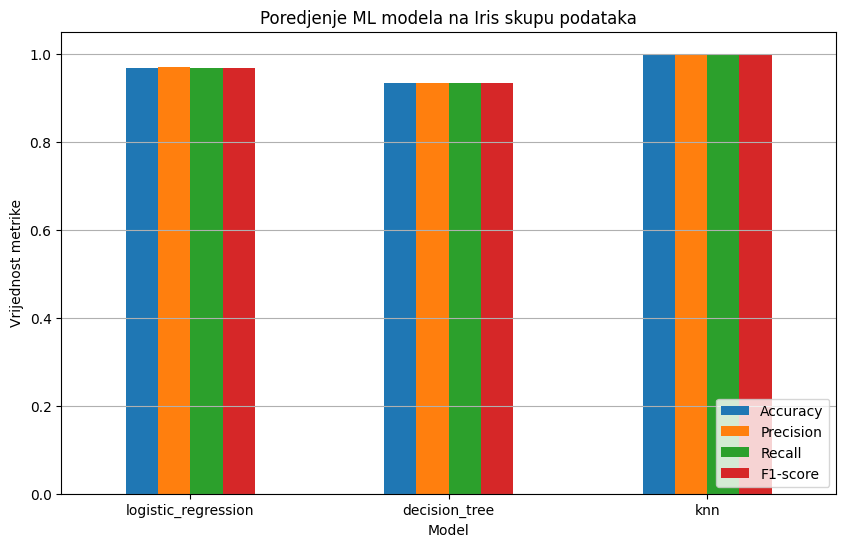

In [22]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Poredjenje ML modela na Iris skupu podataka")
plt.ylabel("Vrijednost metrike")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

In [23]:
try:
    ModelFactory.create_model("nepostojeci_model")
except ValueError as greska:
    print("Uspjesno uhvacena greska:", greska)

Uspjesno uhvacena greska: Nepoznat model: nepostojeci_model



# 7. Organizacija projekta

Glavna implementacija frameworka nalazi se u fajlu `mini_projekat_2.py`, dok se automatski testovi nalaze u posebnom fajlu `test_mini_projekat_2.py`.


In [24]:

%%writefile mini_projekat_2.py

import time
from abc import ABC, abstractmethod
from functools import wraps

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


# FACTORY PATTERN

class MLModel(ABC):

    @abstractmethod
    def train(self, X, y):
        pass

    @abstractmethod
    def predict(self, X):
        pass


class LogisticRegressionModel(MLModel):

    def __init__(self):
        self.model = LogisticRegression(max_iter=200)

    def train(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)


class DecisionTreeModel(MLModel):

    def __init__(self):
        self.model = DecisionTreeClassifier(random_state=42)

    def train(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)


class KNNModel(MLModel):

    def __init__(self):
        self.model = KNeighborsClassifier(n_neighbors=5)

    def train(self, X, y):
        self.model.fit(X, y)

    def predict(self, X):
        return self.model.predict(X)


class ModelFactory:

    @staticmethod
    def create_model(model_type: str) -> MLModel:

        models = {
            "logistic_regression": LogisticRegressionModel,
            "decision_tree": DecisionTreeModel,
            "knn": KNNModel,
        }

        if model_type not in models:
            raise ValueError(f"Nepoznat model: {model_type}")

        return models[model_type]()


# STRATEGY PATTERN

class MetricStrategy(ABC):

    @abstractmethod
    def calculate(self, y_true, y_pred):
        pass


class AccuracyStrategy(MetricStrategy):

    def calculate(self, y_true, y_pred):
        return accuracy_score(y_true, y_pred)


class PrecisionStrategy(MetricStrategy):

    def calculate(self, y_true, y_pred):
        return precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        )


class RecallStrategy(MetricStrategy):

    def calculate(self, y_true, y_pred):
        return recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        )


class F1Strategy(MetricStrategy):

    def calculate(self, y_true, y_pred):
        return f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )


# OBSERVER PATTERN

class Observer(ABC):

    @abstractmethod
    def update(self, message: str):
        pass


class TrainingLogger(Observer):

    def update(self, message: str):
        print(f"[OBSERVER] {message}")


class ExperimentMonitor:

    def __init__(self):
        self.observers = []

    def subscribe(self, observer: Observer):
        self.observers.append(observer)

    def notify(self, message: str):
        for observer in self.observers:
            observer.update(message)


# DECORATOR PATTERN

def measure_time(function):

    @wraps(function)
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = function(*args, **kwargs)
        end = time.perf_counter()

        print(
            f"[DECORATOR] Vrijeme izvrsavanja: "
            f"{end - start:.6f} sekundi"
        )

        return result

    return wrapper


# TEMPLATE METHOD PATTERN

class ExperimentTemplate(ABC):

    def __init__(self, model, metrics, monitor):
        self.model = model
        self.metrics = metrics
        self.monitor = monitor
        self.results = {}

    def run(self, X_train, X_test, y_train, y_test):
        self.monitor.notify("Eksperiment je zapocet.")

        self.prepare_data(X_train, X_test, y_train, y_test)
        self.train_model()
        self.evaluate_model()
        self.show_results()

        self.monitor.notify("Eksperiment je zavrsen.")

        return self.results

    @abstractmethod
    def prepare_data(self, X_train, X_test, y_train, y_test):
        pass

    def train_model(self):
        self.monitor.notify("Treniranje modela je zapoceto.")
        self.model.train(self.X_train, self.y_train)
        self.monitor.notify("Treniranje modela je zavrseno.")

    def evaluate_model(self):
        predictions = self.model.predict(self.X_test)

        for name, metric in self.metrics.items():
            self.results[name] = metric.calculate(
                self.y_test, predictions
            )

    def show_results(self):
        print("Rezultati eksperimenta:")

        for name, value in self.results.items():
            print(f"{name}: {value:.4f}")


class ClassificationExperiment(ExperimentTemplate):

    def prepare_data(self, X_train, X_test, y_train, y_test):
        self.X_train = X_train
        self.X_test = X_test
        self.y_train = y_train
        self.y_test = y_test


# POVEZIVANJE SVIH OBRAZACA

@measure_time
def run_experiment(model_name, X_train, X_test, y_train, y_test):

    model = ModelFactory.create_model(model_name)

    metrics = {
        "Accuracy": AccuracyStrategy(),
        "Precision": PrecisionStrategy(),
        "Recall": RecallStrategy(),
        "F1-score": F1Strategy(),
    }

    monitor = ExperimentMonitor()
    monitor.subscribe(TrainingLogger())

    experiment = ClassificationExperiment(
        model=model,
        metrics=metrics,
        monitor=monitor
    )

    return experiment.run(
        X_train, X_test, y_train, y_test
    )


# DEMONSTRACIJA NA IRIS SKUPU PODATAKA

def main():

    iris = load_iris()
    X = iris.data
    y = iris.target

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    model_names = [
        "logistic_regression",
        "decision_tree",
        "knn",
    ]

    all_results = []

    for model_name in model_names:
        print("\n" + "=" * 50)
        print("MODEL:", model_name.upper())
        print("=" * 50)

        results = run_experiment(
            model_name,
            X_train,
            X_test,
            y_train,
            y_test
        )

        results["Model"] = model_name
        all_results.append(results)

    for result in all_results:
        print(result)


if __name__ == "__main__":
    main()


Writing mini_projekat_2.py


In [25]:
!python mini_projekat_2.py


MODEL: LOGISTIC_REGRESSION
[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Treniranje modela je zapoceto.
[OBSERVER] Treniranje modela je zavrseno.
Rezultati eksperimenta:
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1-score: 0.9666
[OBSERVER] Eksperiment je zavrsen.
[DECORATOR] Vrijeme izvrsavanja: 0.043786 sekundi

MODEL: DECISION_TREE
[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Treniranje modela je zapoceto.
[OBSERVER] Treniranje modela je zavrseno.
Rezultati eksperimenta:
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333
[OBSERVER] Eksperiment je zavrsen.
[DECORATOR] Vrijeme izvrsavanja: 0.010385 sekundi

MODEL: KNN
[OBSERVER] Eksperiment je zapocet.
[OBSERVER] Treniranje modela je zapoceto.
[OBSERVER] Treniranje modela je zavrseno.
Rezultati eksperimenta:
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
[OBSERVER] Eksperiment je zavrsen.
[DECORATOR] Vrijeme izvrsavanja: 0.019698 sekundi
{'Accuracy': 0.9666666666666667, 'Precision': 0.96969

In [26]:

%%writefile test_mini_projekat_2.py

import pytest
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from mini_projekat_2 import (
    ModelFactory,
    LogisticRegressionModel,
    DecisionTreeModel,
    KNNModel,
    AccuracyStrategy,
    PrecisionStrategy,
    RecallStrategy,
    F1Strategy,
    ExperimentMonitor,
    Observer,
    run_experiment,
)


def test_factory_kreira_logisticku_regresiju():
    model = ModelFactory.create_model("logistic_regression")
    assert isinstance(model, LogisticRegressionModel)


def test_factory_kreira_stablo_odlucivanja():
    model = ModelFactory.create_model("decision_tree")
    assert isinstance(model, DecisionTreeModel)


def test_factory_kreira_knn():
    model = ModelFactory.create_model("knn")
    assert isinstance(model, KNNModel)


def test_factory_nepoznat_model():
    with pytest.raises(ValueError):
        ModelFactory.create_model("nepostojeci")


def test_strategy_metrike():
    y_true = [0, 1, 2, 1]
    y_pred = [0, 1, 2, 0]

    strategies = [
        AccuracyStrategy(),
        PrecisionStrategy(),
        RecallStrategy(),
        F1Strategy(),
    ]

    for strategy in strategies:
        rezultat = strategy.calculate(y_true, y_pred)
        assert 0 <= rezultat <= 1


def test_observer_prima_obavjestenje():

    class TestObserver(Observer):

        def __init__(self):
            self.messages = []

        def update(self, message):
            self.messages.append(message)

    monitor = ExperimentMonitor()
    observer = TestObserver()

    monitor.subscribe(observer)
    monitor.notify("Test poruka")

    assert observer.messages == ["Test poruka"]


def test_eksperiment_vraca_rezultate():
    iris = load_iris()

    X_train, X_test, y_train, y_test = train_test_split(
        iris.data,
        iris.target,
        test_size=0.2,
        random_state=42,
        stratify=iris.target
    )

    results = run_experiment(
        "knn",
        X_train,
        X_test,
        y_train,
        y_test
    )

    assert "Accuracy" in results
    assert "Precision" in results
    assert "Recall" in results
    assert "F1-score" in results


Writing test_mini_projekat_2.py


In [27]:
!pytest -q test_mini_projekat_2.py

.......                                                                  [100%]
7 passed in 2.03s


In [30]:
!pip install ruff

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 30.2 MB/s  0:00:00


In [31]:
!ruff check mini_projekat_2.py test_mini_projekat_2.py

I001 [*] Import block is un-sorted or un-formatted
  --> mini_projekat_2.py:2:1
   |
 2 | / import time
 3 | | from abc import ABC, abstractmethod
 4 | | from functools import wraps
 5 | |
 6 | | from sklearn.datasets import load_iris
 7 | | from sklearn.model_selection import train_test_split
 8 | | from sklearn.linear_model import LogisticRegression
 9 | | from sklearn.tree import DecisionTreeClassifier
10 | | from sklearn.neighbors import KNeighborsClassifier
11 | | from sklearn.metrics import (
12 | |     accuracy_score,
13 | |     precision_score,
14 | |     recall_score,
15 | |     f1_score,
16 | | )
   | |_^
help: Organize imports
   |
6  | from sklearn.datasets import load_iris
   - from sklearn.model_selection import train_test_split
7  | from sklearn.linear_model import LogisticRegression
   - from sklearn.tree import DecisionTreeClassifier
   - from sklearn.neighbors import KNeighborsClassifier
8  | from sklearn.metrics import (
9  |     accuracy_score,
10 +     f1_score,
11

In [32]:
!ruff check --fix mini_projekat_2.py test_mini_projekat_2.py

Found 2 errors (2 fixed, 0 remaining).


In [33]:
!ruff check mini_projekat_2.py test_mini_projekat_2.py

All checks passed!


In [34]:
!pytest -q

.......                                                                  [100%]
7 passed in 2.23s


In [35]:

%%writefile README_mini_projekat_2.md

# Mini projekat 2 – ML eksperimentalni okvir

**Predmet:** Napredno programiranje
**Student:** Ivona Dabović
**Broj indeksa:** 26/019

## 1. Opis projekta

Cilj projekta je razvoj jednostavnog okvira za izvođenje eksperimenata mašinskog učenja (Machine Learning), uz primjenu objektno-orijentisanog programiranja i projektnih obrazaca (Design Patterns).

Okvir omogućava kreiranje različitih modela, treniranje, evaluaciju pomoću više metrika, praćenje procesa i mjerenje vremena izvršavanja.

Za demonstraciju je korišćen Iris skup podataka iz biblioteke Scikit-learn.

## 2. Korišćeni alati i biblioteke

- Python
- Scikit-learn
- NumPy
- Pandas
- Pytest
- Ruff
- Google Colab

## 3. Iris skup podataka

Iris je skup podataka koji sadrži 150 uzoraka cvijeća irisa, četiri numeričke karakteristike i tri klase:

- Setosa
- Versicolor
- Virginica

Podaci su podijeljeni na trening i test skup u odnosu 80:20. Korišćen je `random_state=42`, kao i stratifikovana podjela, kako bi zastupljenost klasa bila očuvana.

## 4. Primijenjeni projektni obrasci

### Factory Pattern

Koristi se za kreiranje modela na osnovu naziva modela. Klasa `ModelFactory` omogućava kreiranje tri različita klasifikaciona modela:

- Logistic Regression
- Decision Tree
- K-Nearest Neighbors (KNN)

Na ovaj način ostatak programa ne mora direktno da poznaje način kreiranja svakog modela.

### Strategy Pattern

Koristi se za implementaciju različitih metrika evaluacije. Svaka metrika ima sopstvenu klasu:

- Accuracy
- Precision
- Recall
- F1-score

Metrike se mogu koristiti i mijenjati nezavisno jedna od druge.

### Observer Pattern

Omogućava praćenje procesa izvođenja eksperimenta. Klasa `ExperimentMonitor` obavještava registrovane posmatrače o događajima, dok `TrainingLogger` prikazuje poruke o početku i završetku pojedinih faza.

### Template Method Pattern

Klasa `ExperimentTemplate` definiše osnovni redosljed koraka eksperimenta:

1. Priprema podataka
2. Treniranje modela
3. Evaluacija modela
4. Prikaz rezultata

Klasa `ClassificationExperiment` implementira pripremu podataka za klasifikacioni eksperiment.

### Decorator Pattern

Dekorator `measure_time` mjeri vrijeme izvršavanja funkcije `run_experiment`, bez potrebe da se mijenja njena osnovna logika.

## 5. Rezultati eksperimenata

Na Iris skupu podataka testirana su tri klasifikaciona modela.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.9667 | 0.9697 | 0.9667 | 0.9666 |
| Decision Tree | 0.9333 | 0.9333 | 0.9333 | 0.9333 |
| KNN | 1.0000 | 1.0000 | 1.0000 | 1.0000 |

U ovom eksperimentu KNN model ostvario je najbolje rezultate na test skupu. Rezultati se odnose na konkretnu podjelu podataka i ne predstavljaju garanciju istih performansi na drugim skupovima podataka.

## 6. Testiranje

Za testiranje je korišćen Pytest.

Implementirano je sedam testova koji provjeravaju:

1. Kreiranje Logistic Regression modela.
2. Kreiranje Decision Tree modela.
3. Kreiranje KNN modela.
4. Reakciju Factory obrasca na nepoznat model.
5. Izračunavanje metrika.
6. Funkcionisanje Observer obrasca.
7. Izvođenje eksperimenta i vraćanje rezultata.

Rezultat testiranja:

`7 passed`

Dodatno je izvršena provjera kvaliteta koda pomoću Ruff alata:

`All checks passed!`

## 7. Pokretanje projekta

Instalacija potrebnih biblioteka:

```bash
pip install scikit-learn pytest ruff
```

Pokretanje programa:

```bash
python mini_projekat_2.py
```

Pokretanje testova:

```bash
pytest -q
```

Provjera kvaliteta koda:

```bash
ruff check mini_projekat_2.py test_mini_projekat_2.py
```

## 8. Dijagram klasa

```mermaid
classDiagram
    class MLModel {
        +train(X, y)
        +predict(X)
    }

    class LogisticRegressionModel
    class DecisionTreeModel
    class KNNModel

    MLModel <|-- LogisticRegressionModel
    MLModel <|-- DecisionTreeModel
    MLModel <|-- KNNModel

    class ModelFactory {
        +create_model(model_type)
    }

    ModelFactory ..> MLModel

    class MetricStrategy {
        +calculate(y_true, y_pred)
    }

    class AccuracyStrategy
    class PrecisionStrategy
    class RecallStrategy
    class F1Strategy

    MetricStrategy <|-- AccuracyStrategy
    MetricStrategy <|-- PrecisionStrategy
    MetricStrategy <|-- RecallStrategy
    MetricStrategy <|-- F1Strategy

    class Observer {
        +update(message)
    }

    class TrainingLogger
    Observer <|-- TrainingLogger

    class ExperimentMonitor {
        +subscribe(observer)
        +notify(message)
    }

    ExperimentMonitor --> Observer

    class ExperimentTemplate {
        +run(X_train, X_test, y_train, y_test)
        +prepare_data()
        +train_model()
        +evaluate_model()
        +show_results()
    }

    class ClassificationExperiment
    ExperimentTemplate <|-- ClassificationExperiment

    ExperimentTemplate --> MLModel
    ExperimentTemplate --> MetricStrategy
    ExperimentTemplate --> ExperimentMonitor
```

## 9. Upotreba AI alata

AI alat je korišćen kao pomoć pri razumijevanju projektnih obrazaca, organizaciji strukture programa, pisanju i ispravljanju koda, kao i pri pripremi testova i dokumentacije.

Dobijena rješenja su provjerena kroz izvršavanje programa, Pytest testove i Ruff provjeru kvaliteta koda.


Writing README_mini_projekat_2.md


In [36]:
!ls -l mini_projekat_2.py test_mini_projekat_2.py README_mini_projekat_2.md

-rw-r--r-- 1 root root 6343 Nov 20 16:50 mini_projekat_2.py
-rw-r--r-- 1 root root 5307 Nov 20 16:53 README_mini_projekat_2.md
-rw-r--r-- 1 root root 2143 Nov 20 16:50 test_mini_projekat_2.py


In [37]:
from google.colab import files

files.download("mini_projekat_2.py")
files.download("test_mini_projekat_2.py")
files.download("README_mini_projekat_2.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>